# Replicating Piterbarg & Van Der Helm (2026) with `slidingcurve`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pedronahum/sliding-curve/blob/main/notebooks/replicate_paper.ipynb)

This notebook reproduces the numerical results of Section 9 of

> V. Piterbarg and W. Van Der Helm, *Term Premia and Bond Convexity: Sliding
> Curves, Trading Strategies, and Model Impact* (6 November 2026)

with [`slidingcurve`](https://github.com/pedronahum/sliding-curve), an independent JAX implementation of the
paper's quasi-Gaussian (Cheyette) model simulated in the physical measure defined by the
sliding-curve condition. It was written from the paper; it is not the authors' code.

Each section rebuilds one group of figures and puts the paper's values next to this code's,
both as a plot (paper: open circles) and as a table. The paper's curves, smile quotes and
plotted results were read off its figure images, accurate to a few tenths of a basis point,
and ship with the package (`markets.paper_figures()`).

| Section | Paper | What is reproduced |
|---|---|---|
| 1 | Figure 2 | Gaussian yield decomposition `Y = Y_eh + theta - gamma`, Monte Carlo against closed forms |
| 2 | Figures 3, 6 | Convexity as the skew `b` goes from 0 to 1, on two curves |
| 3 | Figure 4 | Yield-option smiles by skew (a bug in the paper, since confirmed by the authors) |
| 4 | Figures 7-9 | Stochastic volatility: convexity at fixed `sigma` and at fixed at-the-money vol |
| 5 | Figures 10-12 | The 21-Aug-2026 USD curve: calibration to the 20y x 5y smile and the decomposition |
| 6 | Figure 13 | Short-rate densities under the physical measure |
| 7 | | A scorecard of every headline number against the paper |

**Runtime.** Everything runs on a CPU runtime. A GPU runtime (*Runtime → Change runtime
type → T4 GPU*) runs the same code 10-27x faster. The `PRECISION` setting below picks the
number of Monte-Carlo paths. `"quick"` (16,384 paths) takes about two minutes on two CPU
cores and gives most numbers to within a basis point or two of the `"paper"` setting.
`"paper"` (65,536 paths) uses the path counts behind the repository's published comparison,
`docs/paper_results.md`, and takes a few times longer.

All numbers are in basis points unless stated.

## 0. Setup

In [1]:
# Install slidingcurve from GitHub (skipped when it is already importable)
try:
    import slidingcurve  # noqa: F401
except ImportError:
    %pip install -q "git+https://github.com/pedronahum/sliding-curve.git"

In [2]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slidingcurve import (Model, bachelier as bl, calibration, decompose, gaussian as g,
                          markets, pricing as pr, simulate, time_grid, volscale)

# "quick": 2**14 paths, a few minutes on a CPU runtime.
# "paper": 2**16 paths (2**15 for the calibrations), the settings of docs/paper_results.md.
PRECISION = "quick"  # @param ["quick", "paper"]

PATHS = {"quick": 2**14, "paper": 2**16}[PRECISION]
FIT_PATHS = {"quick": 2**14, "paper": 2**15}[PRECISION]
BP = 1e4
SCORECARD = []          # (section, quantity, this code, paper) rows, collected as we go


def score(section, quantity, mine, paper):
    SCORECARD.append(dict(section=section, quantity=quantity, this_code=float(mine), paper=float(paper)))


def nearest(t_ref, values, T):
    """The digitised value at the maturity closest to T."""
    t_ref = np.asarray(t_ref)
    return float(np.asarray(values, dtype=float)[int(np.argmin(np.abs(t_ref - T)))])


class timer:
    def __enter__(self):
        self.t0 = time.perf_counter()
    def __exit__(self, *exc):
        print(f"[{time.perf_counter() - self.t0:.1f}s]")


plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.2f}".format
print(f"JAX {jax.__version__} on {jax.devices()[0].platform.upper()}; "
      f"{PATHS:,} paths ({FIT_PATHS:,} in calibrations); float64: {jax.config.jax_enable_x64}")

JAX 0.10.2 on CPU; 16,384 paths (16,384 in calibrations); float64: True


### The model in one paragraph

The short rate follows a one-factor quasi-Gaussian model with mean reversion `kappa`, local
volatility `sigma_r = sigma * Ybar(t) * (1 + b * (Y - Ybar) / Ybar)` driven by the benchmark
yield `Y` of tenor `delta`, and optionally a CIR variance factor with vol-of-vol `eta`. In
the physical measure the drift is fixed by the *sliding-curve* condition: the benchmark yield
of fixed tenor is a martingale, so the curve "slides" rather than rolls. The yield of every
maturity then splits into

`Y(0, T) = Y_eh(T) + theta(T) - gamma(T)`

the expectations-hypothesis yield, the term premium and the convexity. `simulate` returns the
path means of the state on a time grid and `decompose` turns them into all three terms for
every maturity at once; its `residual` is the closure of the identity.

The settings throughout are the paper's Section 9.1 baseline: `delta = 5`, `kappa = 0.03`,
monthly steps for the decomposition, 24 steps a year for pricing, and the unweighted bootstrap
volatility scaling `Ybar` of (79)-(81) on a monthly expiry grid.

## 1. The Gaussian decomposition (Section 9.1, Figure 2)

Baseline curve, `b = 0`, `eta = 0`, `sigma = 1%`. In this case the model is Gaussian, and
Appendix D gives each term in closed form, so the simulation has an exact oracle.

In [3]:
curve = markets.paper_curve("baseline")
figs = markets.paper_figures()
fig2 = figs["fig2"]
model = Model(kappa=0.03, delta=5.0, sigma=0.01)
t40 = time_grid(40.0, steps_per_year=12)
mats40 = jnp.arange(1.0, 41.0)

with timer():
    ybar = volscale.ybar_zeroth(curve, model.delta, t40)          # immaterial at b = 0
    dec = decompose(simulate(model, curve, t40, ybar, jax.random.PRNGKey(0), n_paths=PATHS),
                    model, curve, mats40)
exact = np.array([[g.yield_eh(curve, model.kappa, model.delta, model.sigma, T),
                   g.term_premium(curve, model.kappa, model.delta, model.sigma, T),
                   g.convexity(model.kappa, model.sigma, T)] for T in np.asarray(mats40)])
mc = np.stack([dec.y_eh, dec.theta, dec.gamma], 1)
paper = {k: np.array([nearest(fig2["T"], fig2[k], T) for T in np.asarray(mats40)])
         for k in ("Y_eh", "theta", "gamma")}

print(f"max |Monte Carlo - closed form| = {BP * np.max(np.abs(mc - exact)):.3f}bp")
for i, k in enumerate(("Y_eh", "theta", "gamma")):
    print(f"max |closed form - Figure 2|, {k:5s} = {np.max(np.abs(BP * exact[:, i] - paper[k])):.2f}bp")
print(f"max |residual of the identity| = {BP * np.max(np.abs(dec.residual)):.4f}bp")

rows = np.array([9, 19, 29, 39])
pd.DataFrame({"T": np.asarray(mats40)[rows].astype(int),
              "Y_eh MC": BP * dec.y_eh[rows], "Y_eh paper": paper["Y_eh"][rows],
              "theta MC": BP * dec.theta[rows], "theta paper": paper["theta"][rows],
              "gamma MC": BP * dec.gamma[rows], "gamma closed form": BP * exact[rows, 2],
              "gamma paper": paper["gamma"][rows]}).set_index("T")

[3.5s]


max |Monte Carlo - closed form| = 0.002bp
max |closed form - Figure 2|, Y_eh  = 0.24bp
max |closed form - Figure 2|, theta = 0.12bp
max |closed form - Figure 2|, gamma = 0.08bp
max |residual of the identity| = 0.0025bp


,Y_eh MC,Y_eh paper,theta MC,theta paper,gamma MC,gamma closed form,gamma paper
T,,,,,,,
10,300.33,300.30,62.23,62.20,13.39,13.39,13.40
20,300.62,300.61,113.73,113.75,43.54,43.54,43.60
30,302.63,302.67,150.93,150.95,80.55,80.55,80.56
40,304.94,304.80,176.30,176.41,119.00,119.00,119.08


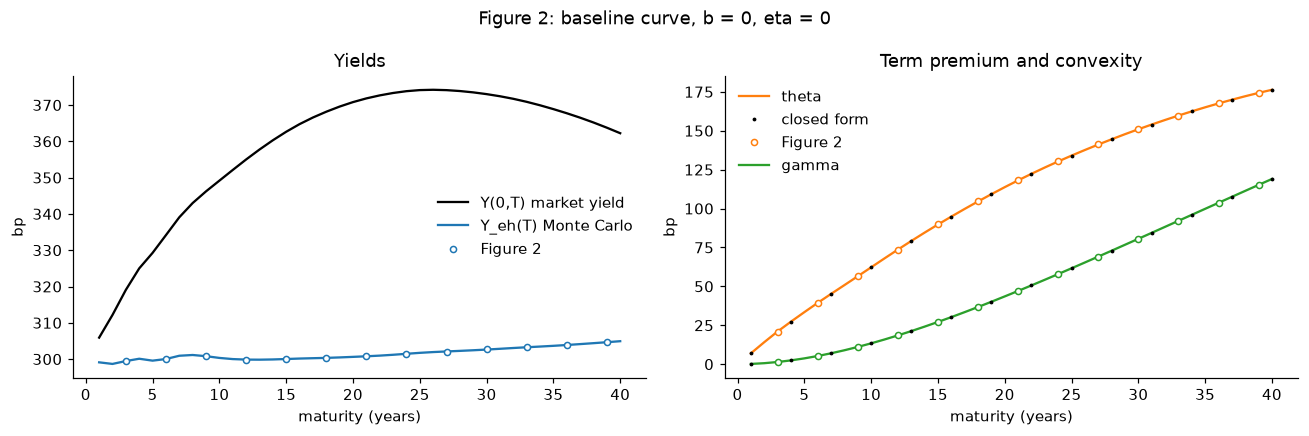

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
ft = np.asarray(fig2["T"])
a.plot(dec.T, BP * dec.y, "k", label="Y(0,T) market yield")
a.plot(dec.T, BP * dec.y_eh, "C0", label="Y_eh(T) Monte Carlo")
a.plot(ft[11::12], np.asarray(fig2["Y_eh"], dtype=float)[11::12], "o", ms=4, color="C0",
       mfc="white", label="Figure 2")
a.set(xlabel="maturity (years)", ylabel="bp", title="Yields")
for i, k in enumerate(("theta", "gamma")):
    b.plot(dec.T, BP * getattr(dec, k), color=f"C{i+1}", label=k)
    b.plot(dec.T[::3], BP * exact[::3, i + 1], "k.", ms=3, label="closed form" if i == 0 else None)
    b.plot(ft[11::12], np.asarray(fig2[k], dtype=float)[11::12], "o", ms=4, color=f"C{i+1}",
           mfc="white", label="Figure 2" if i == 0 else None)
b.set(xlabel="maturity (years)", ylabel="bp", title="Term premium and convexity")
for ax in (a, b):
    ax.legend(frameon=False)
fig.suptitle("Figure 2: baseline curve, b = 0, eta = 0")
plt.tight_layout(); plt.show()

for T in (10, 20, 40):
    score("Fig 2", f"gamma({T}y)", BP * dec.gamma[T - 1], nearest(fig2["T"], fig2["gamma"], T))
    score("Fig 2", f"theta({T}y)", BP * dec.theta[T - 1], nearest(fig2["T"], fig2["theta"], T))

**Also in Section 9.1: Gaussian swaptions against Jamshidian.** At `b = 0` swaption prices
have an exact closed form, which the forward-measure pricer used by every calibration should
reproduce to within Monte-Carlo error.

In [5]:
swp = pr.Swaption.regular(10.0, 5.0)                  # 10y x 5y payer swaption
fwd = float(pr.forward_swap_rate(curve, swp))
strikes = fwd + 1e-4 * np.array([-100.0, 0.0, 100.0])
ybar_fn = lambda t: volscale.ybar_zeroth(curve, model.delta, t)
mc_p, mc_se = pr.swaption_prices(model, curve, swp, jnp.asarray(strikes), ybar_fn,
                                 jax.random.PRNGKey(0), n_paths=PATHS)
jam = [g.payer_swaption(curve, model.kappa, model.sigma, swp.expiry, swp.pay_times, swp.accruals, k)
       for k in strikes]
pd.DataFrame({"strike - forward (bp)": [-100, 0, 100],
              "Monte Carlo (bp of notional)": BP * np.asarray(mc_p),
              "Jamshidian (bp)": BP * np.asarray(jam, dtype=float),
              "MC s.e. (bp)": BP * np.asarray(mc_se)}).set_index("strike - forward (bp)")

,Monte Carlo (bp of notional),Jamshidian (bp),MC s.e. (bp)
strike - forward (bp),,,
-100,512.21,511.16,2.00
0,330.02,329.26,2.42
100,196.77,195.50,2.29


## 2. Skew and convexity (Section 9.2, Figures 3 and 6)

`sigma = 1%`, `eta = 0`, with the skew `b` swept from 0 to 1 on the baseline curve (Figure 3)
and the steeper curve of Figure 5 (Figure 6). The volatility scaling `Ybar` is recalibrated
for every `b` by the unweighted bootstrap of (81), so that at-the-money caplets on the 5y
rate keep their price as `b` moves.

Convexity at 40 years is matched within Monte-Carlo error at low skew, and falls 1.7-2.6%
short at `b >= 0.5`. That residual sits inside the sensitivity to the volatility cap of
Remark 8, which the paper does not define precisely (`docs/investigation.md`, A2).

In [6]:
SKEWS = (0.0, 0.25, 0.5, 0.75, 1.0)
CASES = {"baseline": ("fig3", "Baseline curve (Figure 3)"), "steep": ("fig6", "Steep curve (Figure 6)")}
grid40 = volscale.bootstrap_grid(40.0)
skew_res, table = {}, []
with timer():
    for which, (fig_g, title) in CASES.items():
        c = markets.paper_curve(which)
        ref_t = np.asarray(figs[fig_g]["T"])
        for b in SKEWS:
            m = model._replace(b=b)
            ybar = volscale.bootstrap_fn(c, m, grid40)(t40)
            d = decompose(simulate(m, c, t40, ybar, jax.random.PRNGKey(1), n_paths=PATHS), m, c, mats40)
            ref = np.array(figs[fig_g][f"b={b:.2f}"], dtype=float)
            skew_res[which, b] = (d, ref_t, ref)
            row = {"curve": which, "b": b}
            for T in (10, 20, 30, 40):
                row[f"{T}y"] = BP * float(d.gamma[T - 1])
                row[f"{T}y paper"] = nearest(ref_t, ref, T)
            row["s.e. 40y"] = BP * float(d.gamma_se[-1])
            table.append(row)
            score(f"Fig {fig_g[3:]}", f"gamma(40y), {which}, b = {b}", row["40y"], row["40y paper"])
pd.DataFrame(table).set_index(["curve", "b"])

[7.2s]


10y  10y paper   20y  20y paper    30y  30y paper    40y  \
curve    b                                                                 
baseline 0.00 13.39        NaN 43.54        NaN  80.55      80.65 119.00   
         0.25 13.28        NaN 43.83      43.90  84.82      84.94 143.82   
         0.50 13.50      12.65 46.59      46.73  99.49      99.68 201.28   
         0.75 14.08      13.73 52.50      52.44 125.53     125.41 267.49   
         1.00 15.10      14.94 61.82      61.49 156.44     155.66 323.82   
steep    0.00 13.39        NaN 43.54      44.06  80.55      81.06 119.00   
         0.25 12.97        NaN 41.79        NaN  77.89      77.97 118.22   
         0.50 12.81        NaN 41.63      41.60  80.08      80.12 129.79   
         0.75 12.91      12.49 43.22      43.04  88.07      87.98 154.97   
         1.00 13.30      13.07 46.88      46.61 101.88     101.18 187.56   

               40y paper  s.e. 40y  
curve    b                          
baseline 0.00     119.02      0.00  
         0.25     144.07      0.36  
         0.50     202.12      1.64  
         0.75     267.62      3.30  
         1.00     323.30      5.25  
steep    0.00     119.49      0.00  
         0.25     118.37      0.12  
         0.50     129.95      0.59  
         0.75     154.90      1.61  
         1.00     186.33      2.97

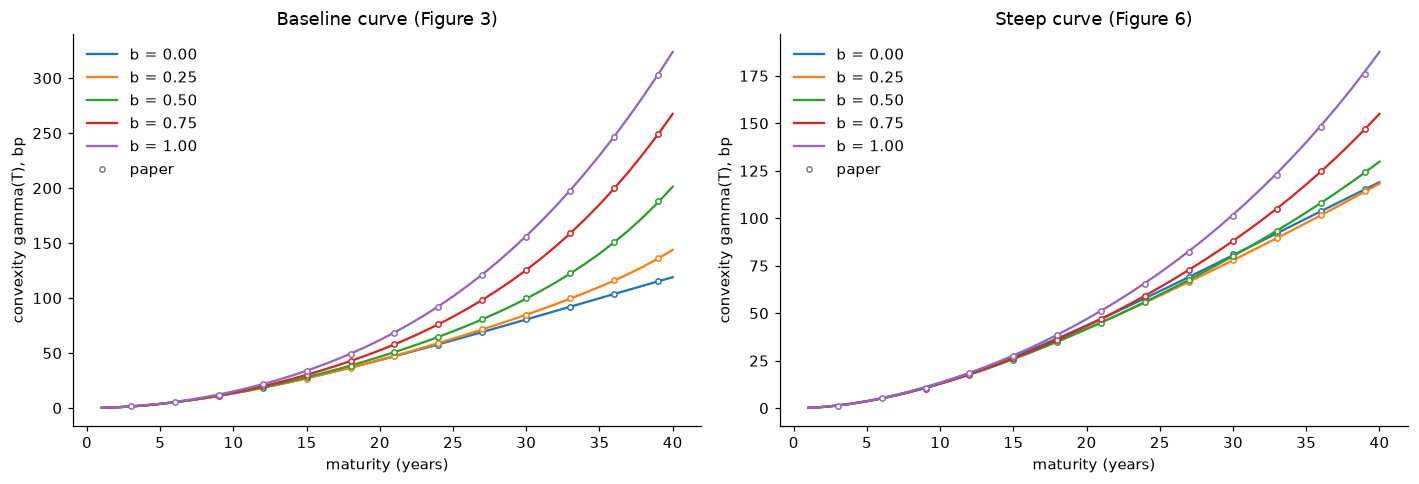

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (which, (_, title)) in zip(axes, CASES.items()):
    for i, b in enumerate(SKEWS):
        d, ref_t, ref = skew_res[which, b]
        ax.plot(d.T, BP * d.gamma, color=f"C{i}", label=f"b = {b:.2f}")
        ax.plot(ref_t[11::12], ref[11::12], "o", ms=3.5, color=f"C{i}", mfc="white")
    ax.plot([], [], "o", ms=3.5, color="grey", mfc="white", label="paper")
    ax.set(xlabel="maturity (years)", ylabel="convexity gamma(T), bp", title=title)
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Smiles by skew (Section 9.2, Figure 4)

**Figure 4 was a bug in the paper's implied-volatility calculation**, confirmed by the authors
on 16 November 2026; a corrected version is to be posted and nothing else in the paper
changes. This section is kept because it shows how the bug was located.

The instrument is the paper's "yield option": a call on the continuously compounded 5y
forward yield at expiry, paid at the end of its window, with normal vols inverted around the
yield's mean (`docs/investigation.md`, A9 pins this down). The at-the-money levels agree with
the paper to about 1bp, but the paper's smiles at `b = 1` are steeper than this code's by a
factor of almost exactly `T / delta` (1, 2, 3, 4 at 5, 10, 15 and 20 years). That fingerprint
pointed at the paper's implied-volatility step. The paper's *text* (at-the-money vol at
`b = 1` about 4bp below `b = 0` at 5y and 6-8bp below at 20y) agrees with this code.

In [8]:
fig4 = figs["fig4"]
grid20 = volscale.bootstrap_grid(20.0)
smile_res, rows = {}, []
with timer():
    for expiry in (5, 10, 15, 20):
        r = fig4[str(expiry)]
        offsets = 1e-4 * np.asarray(r["offsets"])
        for b in SKEWS:
            m = model._replace(b=b)
            _, p, _ = pr.yield_option_prices(m, curve, float(expiry), offsets,
                                             volscale.bootstrap_fn(curve, m, grid20),
                                             jax.random.PRNGKey(0), n_paths=PATHS)
            vols = BP * bl.implied_normal_vol(np.asarray(p), 0.0, offsets, float(expiry))
            smile_res[expiry, b] = (BP * offsets, vols, np.array(r[f"b={b:.2f}"], dtype=float))

    for expiry in (5, 10, 15, 20):
        k, v0, p0 = smile_res[expiry, 0.0]
        k, v1, p1 = smile_res[expiry, 1.0]
        slope = lambda v: (v[7] - v[3]) / (k[7] - k[3])       # +-80bp around the money
        rows.append({"expiry": expiry, "ATM b=0": v0[5], "ATM b=0 paper": p0[5],
                     "ATM b=1": v1[5], "ATM b=1 paper": p1[5],
                     "slope ratio paper / this code (b=1)": slope(p1) / slope(v1),
                     "T / delta": expiry / model.delta})
pd.DataFrame(rows).set_index("expiry")

[13.6s]


,ATM b=0,ATM b=0 paper,ATM b=1,ATM b=1 paper,slope ratio paper / this code (b=1),T / delta
expiry,,,,,,
5,87.74,NaN,83.77,86.04,1.00,1.00
10,80.88,79.08,74.38,80.60,2.04,2.00
15,75.96,74.93,67.55,76.11,3.26,3.00
20,71.58,68.38,62.58,74.27,4.79,4.00


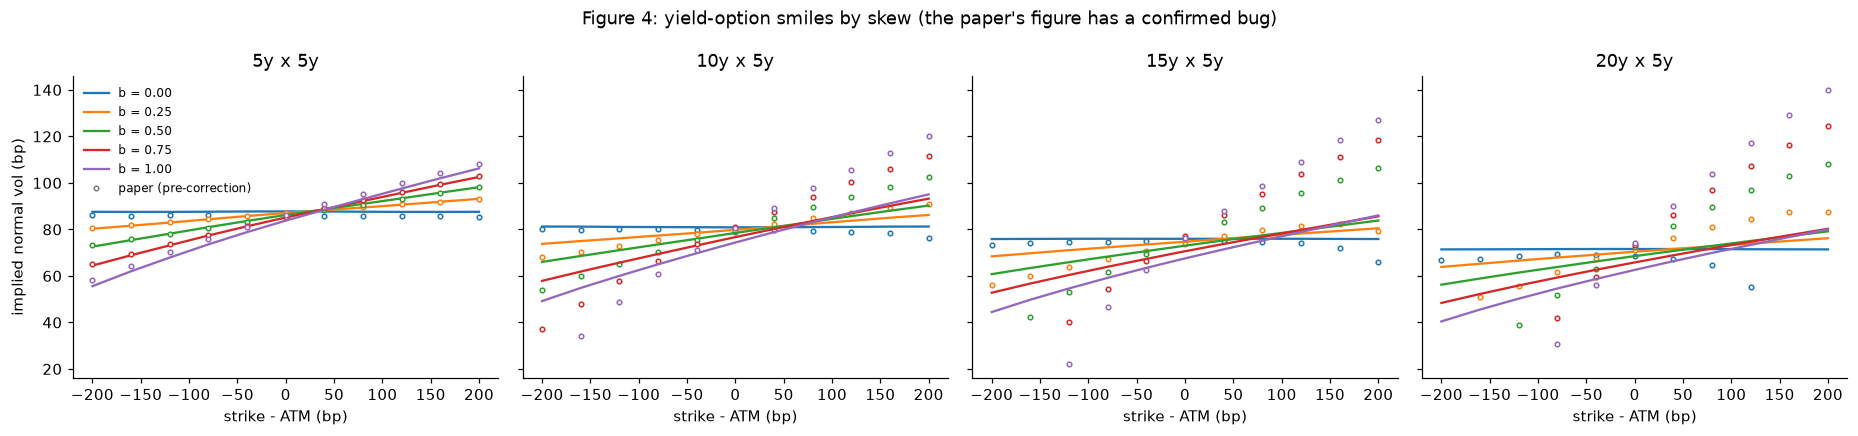

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, expiry in zip(axes, (5, 10, 15, 20)):
    for i, b in enumerate(SKEWS):
        k, vols, paper = smile_res[expiry, b]
        ax.plot(k, vols, color=f"C{i}", label=f"b = {b:.2f}")
        ax.plot(k, paper, "o", ms=3, color=f"C{i}", mfc="white")
    ax.set(xlabel="strike - ATM (bp)", title=f"{expiry}y x 5y")
axes[0].set_ylabel("implied normal vol (bp)")
axes[0].plot([], [], "o", ms=3, color="grey", mfc="white", label="paper (pre-correction)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Figure 4: yield-option smiles by skew (the paper's figure has a confirmed bug)")
plt.tight_layout(); plt.show()

## 4. Stochastic volatility (Section 9.3, Figures 7-9)

Baseline curve, `b = 0`, variance mean reversion `kappa_z = 0.1`, and vol-of-vol `eta` in
{0, 0.5, 1, 1.5}. Three experiments:

- **Figure 7**: convexity with `sigma` left at its `eta = 0` value. It barely moves.
- **Figure 8**: the 20y x 5y yield-option smile at that fixed `sigma`. The at-the-money vol
  falls as `eta` rises (Jensen: `E[sqrt(V)] < sqrt(E[V])`) and the wings lift.
- **Figure 9**: `sigma` recalibrated at each `eta` so that the at-the-money vol is unchanged.
  Now convexity rises steeply with `eta`: this is the paper's model-risk point.

At the `"paper"` setting Figure 9 matches to within 1% up to `eta = 1`; at `eta = 1.5` this
code gives 204.2 +- 1.3bp over four seeds against the paper's 212.8bp, which
`docs/investigation.md` (A3) attributes to sampling noise in the paper's run. At `"quick"`
precision the standard errors in the table are larger, and the `eta = 1.5` value moves by a
few basis points with the seed.

In [10]:
ETAS = (0.0, 0.5, 1.0, 1.5)
EXPIRY = 20.0
sv_base = model._replace(kappa_z=0.1)
fig8, fig9 = figs["fig8"], figs["fig9"]
sv_offsets = 1e-4 * np.asarray(fig8["offsets"])
pkey, skey = jax.random.PRNGKey(0), jax.random.PRNGKey(1)
ybar_fn = lambda t: volscale.ybar_zeroth(curve, sv_base.delta, t)     # unused at b = 0


def yield_smile(m):
    mean, p, _ = pr.yield_option_prices(m, curve, EXPIRY, sv_offsets, ybar_fn, pkey, n_paths=PATHS)
    return float(mean), BP * bl.implied_normal_vol(np.asarray(p), 0.0, sv_offsets, EXPIRY)


def convexity(m):
    return decompose(simulate(m, curve, t40, ybar_fn(t40), skey, n_paths=PATHS), m, curve, mats40)


with timer():
    _, sm0 = yield_smile(sv_base)
    atm0 = sm0[5] / BP
    sv_res, rows = [], []
    for eta in ETAS:
        fixed = sv_base._replace(eta=eta)
        recal = calibration.calibrate_yield_smile(fixed, curve, EXPIRY, sv_offsets[5:6], [atm0],
                                                  free=("sigma",), key=pkey, n_paths=FIT_PATHS).model
        mean, sm = yield_smile(fixed)
        dfix, drec = convexity(fixed), convexity(recal)
        sv_res.append((eta, mean, sm, dfix, recal, drec))
        rows.append({"eta": eta,
                     "ATM vol, sigma fixed": sm[5], "paper (Fig 8)": fig8[f"eta={eta}"][5],
                     "gamma(40y), sigma fixed": BP * float(dfix.gamma[-1]),
                     "recalibrated sigma (%)": 100 * recal.sigma,
                     "gamma(40y), ATM vol fixed": BP * float(drec.gamma[-1]),
                     "paper (Fig 9)": fig9[f"eta={eta}"][-1],
                     "s.e.": BP * float(drec.gamma_se[-1])})
        score("Fig 8", f"ATM vol, eta = {eta}", sm[5], fig8[f"eta={eta}"][5])
        score("Fig 9", f"gamma(40y), eta = {eta}", BP * float(drec.gamma[-1]), fig9[f"eta={eta}"][-1])
pd.DataFrame(rows).set_index("eta")

[18.4s]


,"ATM vol, sigma fixed",paper (Fig 8),"gamma(40y), sigma fixed",recalibrated sigma (%),"gamma(40y), ATM vol fixed",paper (Fig 9),s.e.
eta,,,,,,,
0.00,71.58,71.40,119.00,1.00,119.00,119.15,0.00
0.50,67.53,66.13,118.60,1.06,133.20,133.59,0.51
1.00,60.57,60.87,117.62,1.18,163.64,166.72,1.81
1.50,54.88,53.58,117.01,1.29,195.99,212.76,2.92


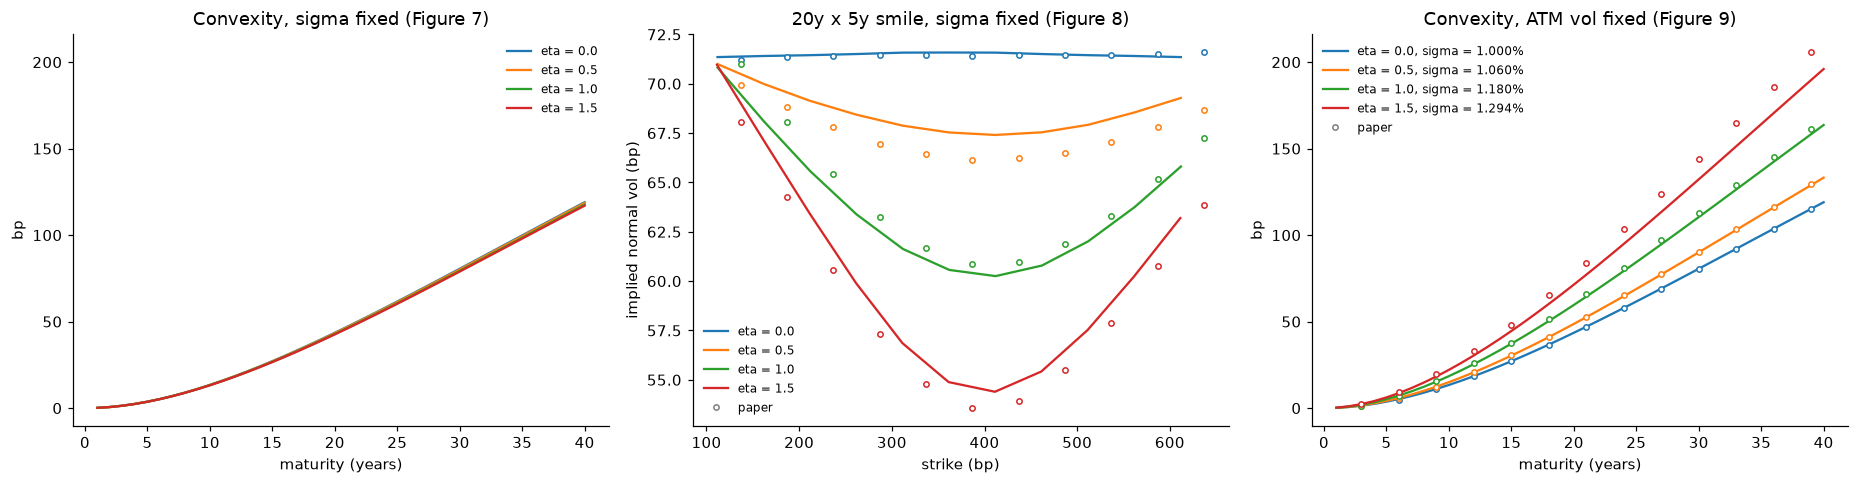

In [11]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(17, 4.5))
ref_t = np.asarray(fig9["T"])
for i, (eta, mean, sm, dfix, recal, drec) in enumerate(sv_res):
    a.plot(dfix.T, BP * dfix.gamma, color=f"C{i}", label=f"eta = {eta}")
    # absolute strikes: this code's are offsets from the yield's mean, the paper's from its
    # at-the-money line at the curve forward (387bp); see docs/investigation.md, A4
    b.plot(BP * (mean + sv_offsets), sm, color=f"C{i}", label=f"eta = {eta}")
    b.plot(387.0 + BP * sv_offsets, np.array(fig8[f"eta={eta}"], dtype=float), "o", ms=3.5,
           color=f"C{i}", mfc="white")
    c.plot(drec.T, BP * drec.gamma, color=f"C{i}", label=f"eta = {eta}, sigma = {100*recal.sigma:.3f}%")
    c.plot(ref_t[11::12], np.array(fig9[f"eta={eta}"], dtype=float)[11::12], "o", ms=3.5,
           color=f"C{i}", mfc="white")
for ax in (b, c):
    ax.plot([], [], "o", ms=3.5, color="grey", mfc="white", label="paper")
a.set(xlabel="maturity (years)", ylabel="bp", title="Convexity, sigma fixed (Figure 7)")
b.set(xlabel="strike (bp)", ylabel="implied normal vol (bp)", title="20y x 5y smile, sigma fixed (Figure 8)")
c.set(xlabel="maturity (years)", ylabel="bp", title="Convexity, ATM vol fixed (Figure 9)")
a.set_ylim(c.get_ylim())
for ax in (a, b, c):
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. The market curve (Section 9.4, Figures 10-12)

The 21-Aug-2026 USD curve and five quotes of the 20y x 5y yield-option smile, read off
Figures 10 and 11. Two calibrations:

- **At-the-money only** (`b = 0`): fit `sigma` to the 82bp at-the-money vol. The Gaussian-twin
  control variate makes this estimate exact at any seed. Paper: `sigma = 1.157%`.
- **With skew**: fit `sigma` and `b` to all five quotes, with the at-the-money quote pinned
  (the paper says it is matched exactly). Paper: `sigma = 1.1999%`, `b = 0.367`.

The paper states two values of `sigma` for the skew fit: 1.12% in the text and 1.1999% in the
caption of Figure 13. Only 1.1999% reproduces Figures 11 and 12 (A10). The five quotes define
a shallow valley in (`sigma`, `b`), so the fit differs slightly from the paper's (at the
`"paper"` setting, 1.196% and 0.354 against 1.1999% and 0.367) and moves along that valley
with the path count and seed. The decomposition is therefore also run at the paper's own
parameters, which separates the engine from the fit: that run matches Figure 12 to a few
tenths of a basis point.

In [12]:
mkt = markets.paper_curve("market")
offsets, market_vols, paper_fit = markets.paper_smile()
start = Model(kappa=0.03, delta=5.0, sigma=0.01)
with timer():
    atm = calibration.calibrate_yield_smile(start, mkt, EXPIRY, offsets[2:3], market_vols[2:3],
                                            free=("sigma",), control_variate=True, n_paths=FIT_PATHS)
    skew = calibration.calibrate_yield_smile(start, mkt, EXPIRY, offsets, market_vols,
                                             free=("sigma", "b"), weights=[1, 1, 30, 1, 1],
                                             n_paths=FIT_PATHS)
print(f"ATM only:  sigma = {100*atm.model.sigma:.4f}%               (paper 1.157%)")
print(f"with skew: sigma = {100*skew.model.sigma:.4f}%, b = {skew.model.b:.3f}   (paper 1.1999%, 0.367)")
score("Sec 9.4", "sigma, ATM fit (%)", 100 * atm.model.sigma, 1.157)
score("Sec 9.4", "sigma, skew fit (%)", 100 * skew.model.sigma, 1.1999)
score("Sec 9.4", "b, skew fit", skew.model.b, 0.367)
pd.DataFrame({"strike - ATM (bp)": BP * offsets, "market": BP * market_vols,
              "paper's fit": BP * paper_fit, "this code's fit": BP * np.asarray(skew.model_vols)}
             ).set_index("strike - ATM (bp)")

[8.5s]
ATM only:  sigma = 1.1573%               (paper 1.157%)
with skew: sigma = 1.1793%, b = 0.363   (paper 1.1999%, 0.367)


,market,paper's fit,this code's fit
strike - ATM (bp),,,
-200.00,77.13,73.35,72.71
-50.00,79.80,79.80,79.76
0.00,82.01,82.01,82.02
50.00,84.77,84.23,84.13
200.00,95.18,90.72,90.31


In [13]:
t30 = time_grid(30.0, steps_per_year=12)
mats30 = jnp.arange(1.0, 31.0)
grid30 = volscale.bootstrap_grid(30.0)
stated = atm.model._replace(sigma=0.011999, b=0.367)
RUNS = {"b = 0 (Figure 10)": (atm.model, "fig10"),
        "skew, this code's fit (Figure 12)": (skew.model, "fig12"),
        "skew, paper's parameters (Figure 12)": (stated, "fig12")}
mkt_res, rows = {}, []
with timer():
    for name, (m, fig_key) in RUNS.items():
        ybar = volscale.bootstrap_fn(mkt, m, grid30)(t30)
        d = decompose(simulate(m, mkt, t30, ybar, jax.random.PRNGKey(1), n_paths=PATHS), m, mkt, mats30)
        ref = figs[fig_key]
        mkt_res[name] = (d, ref)
        for T in (5, 10, 20, 30):
            j, r = T - 1, 4 * T - 1                    # the digitised grid is quarterly
            rows.append({"run": name, "T": T,
                         "Y_eh": BP * float(d.y_eh[j]), "Y_eh paper": ref["Y_eh"][r],
                         "theta": BP * float(d.theta[j]), "theta paper": ref["theta"][r],
                         "gamma": BP * float(d.gamma[j]), "gamma paper": ref["gamma"][r]})
        tag = "Fig 10" if fig_key == "fig10" else "Fig 12"
        score(tag, f"gamma(30y), {name.split(' (')[0]}", BP * float(d.gamma[29]), ref["gamma"][119])
        if fig_key == "fig10":
            for k in ("y_eh", "theta", "gamma"):
                key = {"y_eh": "Y_eh"}.get(k, k)
                score(tag, f"{key}(20y)", BP * float(getattr(d, k)[19]), ref[key][79])
pd.DataFrame(rows).set_index(["run", "T"])

[5.4s]


Y_eh  Y_eh paper  theta  \
run                                  T                              
b = 0 (Figure 10)                    5  380.54      380.60  29.20   
                                     10 370.13      370.13  70.82   
                                     20 372.59      372.60 138.04   
                                     30 377.85      376.44 173.16   
skew, this code's fit (Figure 12)    5  380.31      380.47  29.77   
                                     10 369.84      369.79  72.51   
                                     20 371.38      369.71 145.53   
                                     30 365.08      361.94 211.98   
skew, paper's parameters (Figure 12) 5  380.04      380.47  30.23   
                                     10 369.34      369.79  73.74   
                                     20 370.37      369.71 149.21   
                                     30 361.96      361.94 222.46   

                                         theta paper  gamma  gamma paper  
run                                  T                                    
b = 0 (Figure 10)                    5         29.13   5.00         4.92  
                                     10        70.82  17.93        17.93  
                                     20       137.97  58.32        58.34  
                                     30       174.65 107.88       108.04  
skew, this code's fit (Figure 12)    5         29.70   5.23         5.36  
                                     10        72.76  18.90        19.57  
                                     20       148.57  63.35        65.95  
                                     30       221.74 133.14       140.28  
skew, paper's parameters (Figure 12) 5         29.70   5.42         5.36  
                                     10        72.76  19.61        19.57  
                                     20       148.57  65.96        65.95  
                                     30       221.74 140.45       140.28

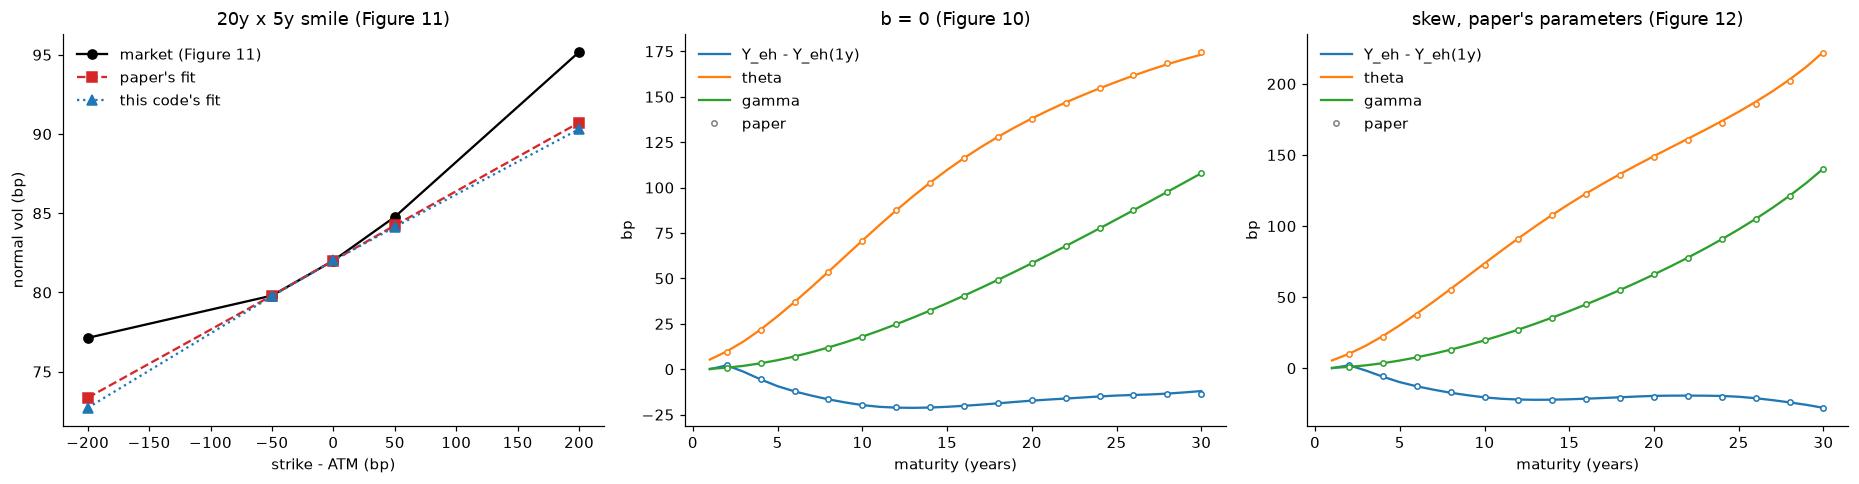

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
k = BP * offsets
axes[0].plot(k, BP * market_vols, "ko-", label="market (Figure 11)")
axes[0].plot(k, BP * paper_fit, "s--", color="C3", label="paper's fit")
axes[0].plot(k, BP * np.asarray(skew.model_vols), "^:", color="C0", label="this code's fit")
axes[0].set(xlabel="strike - ATM (bp)", ylabel="normal vol (bp)", title="20y x 5y smile (Figure 11)")
axes[0].legend(frameon=False)
for ax, name in zip(axes[1:], ("b = 0 (Figure 10)", "skew, paper's parameters (Figure 12)")):
    d, ref = mkt_res[name]
    rt = np.asarray(ref["T"])[7::8]
    for i, (label, mine, key) in enumerate((("Y_eh - Y_eh(1y)", d.y_eh - d.y_eh[0], "Y_eh"),
                                            ("theta", d.theta, "theta"), ("gamma", d.gamma, "gamma"))):
        r = np.array(ref[key], dtype=float)
        r = r - r[3] if key == "Y_eh" else r
        ax.plot(d.T, BP * mine, color=f"C{i}", label=label)
        ax.plot(rt, r[7::8], "o", ms=3.5, color=f"C{i}", mfc="white")
    ax.plot([], [], "o", ms=3.5, color="grey", mfc="white", label="paper")
    ax.set(xlabel="maturity (years)", ylabel="bp", title=name)
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Optional: the three-parameter fit with `eta` free.** Five quotes do not identify
(`sigma`, `b`, `eta`) at Monte-Carlo precision: the fit lies on a valley along which
`gamma(30y)` runs from 137 to 464bp, which is the paper's own conclusion about model risk
(A7). This takes several minutes on a CPU; set `RUN_ETA_FIT = True` to run it.

In [15]:
RUN_ETA_FIT = False  # @param {type:"boolean"}
if RUN_ETA_FIT:
    with timer():
        # start from the skew fit: with eta free there is a second, spurious basin
        full = calibration.calibrate_yield_smile(skew.model._replace(eta=0.5), mkt, EXPIRY, offsets,
                                                 market_vols, free=("sigma", "b", "eta"),
                                                 n_paths=FIT_PATHS)
    print(f"sigma = {100*full.model.sigma:.3f}%, b = {full.model.b:.3f}, eta = {full.model.eta:.3f} "
          f"(paper 1.492%, 0.417, 0.779); max vol error {np.max(np.abs(full.vol_errors_bp)):.2f}bp")

## 6. Short-rate densities (Section 9.4, Figure 13)

The density of the short rate `r(T)` under the physical measure at 10, 20 and 30 years, at the
paper's two calibrations. The paper's text: without skew the standard deviation at 30 years is
"over 600bp" and the probability of a negative rate "around one in four"; with skew the median
is "around zero", the probability of a negative rate "about one half", and the mean 280bp.

In [16]:
from scipy.stats import gaussian_kde

fig13 = figs["fig13"]
r_grid = np.asarray(fig13["r"])
TIMES = (10.0, 20.0, 30.0)
DENS = {"atm": ("ATM calibration: sigma = 1.1572%, b = 0", Model(0.03, 5.0, 0.011572)),
        "skew": ("Skew calibration: sigma = 1.1999%, b = 0.367", Model(0.03, 5.0, 0.011999, b=0.367))}
dens_res, rows = {}, []
with timer():
    for name, (title, m) in DENS.items():
        ybar = volscale.bootstrap_fn(mkt, m, grid30)(t30)
        _, r = simulate(m, mkt, t30, ybar, jax.random.PRNGKey(1), n_paths=PATHS, snapshot_times=TIMES)
        r = BP * np.asarray(r)
        dens_res[name] = r
        for i, T in enumerate(TIMES):
            rows.append({"calibration": name, "T": int(T), "mean": r[i].mean(),
                         "mean paper": fig13[name]["mean"][f"T={T:.0f}"], "median": np.median(r[i]),
                         "st.dev.": r[i].std(), "P(r < 0)": np.mean(r[i] < 0)})
r_atm, r_skew = dens_res["atm"][-1], dens_res["skew"][-1]
score("Fig 13", "st.dev. r(30y), no skew (text: over 600)", r_atm.std(), 600)
score("Fig 13", "P(r(30y) < 0), no skew (text: ~1/4)", r_atm.__lt__(0).mean(), 0.25)
score("Fig 13", "P(r(30y) < 0), skew (text: ~1/2)", r_skew.__lt__(0).mean(), 0.5)
score("Fig 13", "mean r(30y), skew", r_skew.mean(), 280)
pd.DataFrame(rows).set_index(["calibration", "T"])

[1.2s]


mean  mean paper  median  st.dev.  P(r < 0)
calibration T                                               
atm         10 357.78      352.60  357.78   369.92      0.17
            20 385.82      384.50  385.82   524.74      0.23
            30 399.02      391.60  399.02   636.96      0.26
skew        10 356.44      350.80  301.20   380.22      0.17
            20 376.52      375.50  254.86   560.53      0.26
            30 286.61      280.10   25.23   816.54      0.47

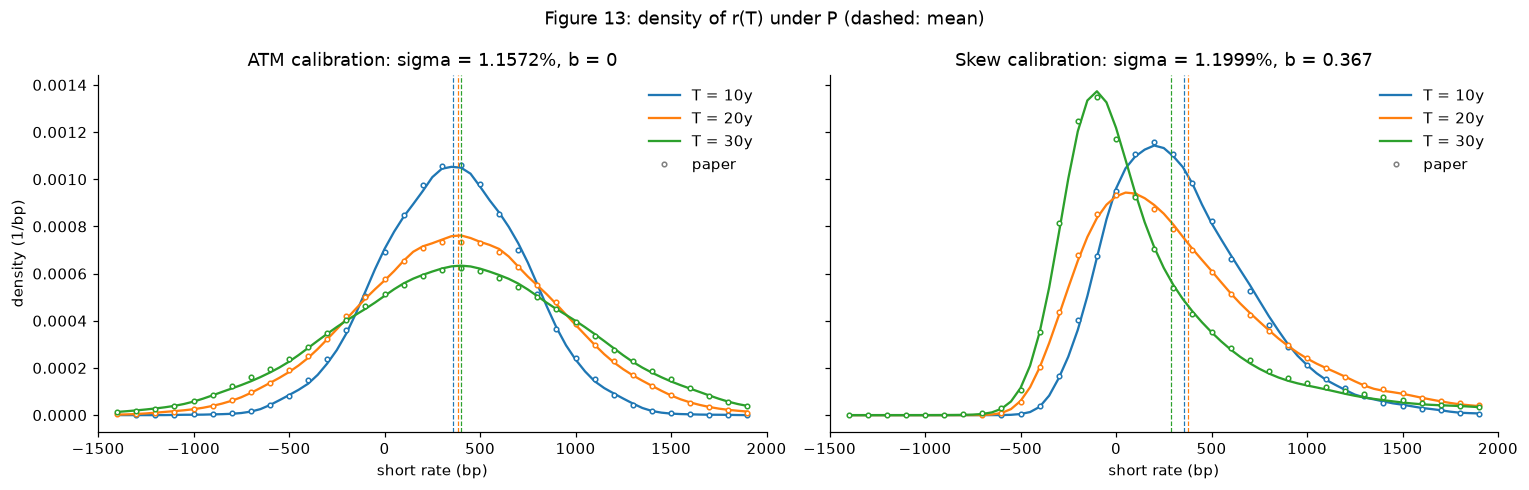

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (name, (title, _)) in zip(axes, DENS.items()):
    for i, T in enumerate(TIMES):
        sample = dens_res[name][i][:: max(1, dens_res[name].shape[1] // 20000)]
        ax.plot(r_grid, gaussian_kde(sample)(r_grid), color=f"C{i}", label=f"T = {T:.0f}y")
        ax.plot(r_grid[::2], np.array(fig13[name]["density"][f"T={T:.0f}"], dtype=float)[::2], "o",
                ms=3, color=f"C{i}", mfc="white")
        ax.axvline(dens_res[name][i].mean(), color=f"C{i}", ls="--", lw=0.8)
    ax.plot([], [], "o", ms=3, color="grey", mfc="white", label="paper")
    ax.set(xlabel="short rate (bp)", title=title, xlim=(-1500, 2000))
    ax.legend(frameon=False)
axes[0].set_ylabel("density (1/bp)")
fig.suptitle("Figure 13: density of r(T) under P (dashed: mean)")
plt.tight_layout(); plt.show()

## 7. Scorecard

Every headline number collected above, against the paper. Differences are in the units of the
quantity (basis points unless the name says otherwise). The values the paper gives only in its
text (Figure 13) are rounded statements such as "around one in four", so their differences
are indicative only. The table is also written to `scorecard.csv`.

In [18]:
sc = pd.DataFrame(SCORECARD)
sc["difference"] = sc["this_code"] - sc["paper"]
sc["relative (%)"] = 100 * sc["difference"] / sc["paper"].abs()
sc.to_csv("scorecard.csv", index=False)
print(f"{PRECISION!r} precision, {PATHS:,} paths")
sc = sc.set_index(["section", "quantity"])
try:                                # colour the relative differences where jinja2 is available
    sc = sc.style.format("{:.3f}").background_gradient(subset=["relative (%)"], cmap="RdBu_r",
                                                       vmin=-5, vmax=5)
except (AttributeError, ImportError):
    pass
sc

'quick' precision, 16,384 paths


### Where to go next

- `docs/paper_results.md` in the repository has the full comparison at the `"paper"`
  settings, and `docs/investigation.md` the log of every discrepancy found and how it was
  closed.
- The `examples/` directory has a script per section; `examples/joshi_calibration.py` runs the
  Section 9.4 workflow on a published test market (Mark Joshi's displaced-diffusion LMM).
- To price a payoff of your own, see "Pricing a payoff of your own" in the
  [README](https://github.com/pedronahum/sliding-curve#pricing-a-payoff-of-your-own).